In [1]:
# Some sample code for importing model which has been downloaded from the HEC

from problems.pdtrp.problem_pdtrp import PDTRPDataset
from problems.pdcvrp.problem_pdcvrp import PDCVRPDataset
from problems.pdtrp_tw.problem_pdtrptw import PDTRPTWDataset
from problems.pdcvrp_tw.problem_pdcvrptw import PDCVRPTWDataset

from torch.utils.data import DataLoader

from utils import load_model, move_to
from train import set_decode_type
import torch
from tqdm import tqdm

use_cuda = torch.cuda.is_available()
device = torch.device("cuda:0" if use_cuda else "cpu")
problem_type = 'PDCVRP'

# if problem_type == 'PDTRP':
#     model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp_20250210T152027'
# elif problem_type == 'PDCVRP':
#     model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdcvrp_20250210T171835'

# dirichlet random 
# model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp_20250220T235527'
# N1 
# model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp-n1_20250220T235529'
# N2
#model_filepath = 'models_HEC/rl-ar-var-20pnn-gnn-max-pdtrp-n2_20250220T235605'

# model, model_args = load_model(model_filepath)

# model.to(device)
# set_decode_type(model, "greedy")
# model.eval()

In [2]:
# Function for plotting solutions
%matplotlib inline
from matplotlib import pyplot as plt

from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import numpy as np

# Code inspired by Google OR Tools plot:
# https://github.com/google/or-tools/blob/fb12c5ded7423d524fc6c95656a9bdc290a81d4d/examples/python/cvrptw_plot.py

def plot_tsp(xy, tour, ax1):
    """
    Plot the TSP tour on matplotlib axis ax1.
    """
    
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    xs, ys = xy[tour].transpose()
    xs, ys = xy[tour].transpose()
    dx = np.roll(xs, -1) - xs
    dy = np.roll(ys, -1) - ys
    d = np.sqrt(dx * dx + dy * dy)
    lengths = d.cumsum()
    
    # Scatter nodes
    ax1.scatter(xs, ys, s=40, color='blue')
    # Starting node
    ax1.scatter([xs[0]], [ys[0]], s=100, color='red')

    #label nodes
    for i, (x, y) in enumerate(xy):
        ax1.text(x, y, str(i), fontsize=12, color='green')
    
    # Arcs
    qv = ax1.quiver(
        xs, ys, dx, dy,
        scale_units='xy',
        angles='xy',
        scale=1,
    )
    
    ax1.set_title('{} nodes, total length {:.2f}'.format(len(tour), lengths[-1]))



In [25]:
%matplotlib inline
from matplotlib import pyplot as plt

from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# Code inspired by Google OR Tools plot:
# https://github.com/google/or-tools/blob/fb12c5ded7423d524fc6c95656a9bdc290a81d4d/examples/python/cvrptw_plot.py

def discrete_cmap(N, base_cmap=None):
  """
    Create an N-bin discrete colormap from the specified input map
    """
  # Note that if base_cmap is a string or None, you can simply do
  #    return plt.cm.get_cmap(base_cmap, N)
  # The following works for string, None, or a colormap instance:

  base = plt.cm.get_cmap(base_cmap)
  color_list = base(np.linspace(0, 1, N))
  cmap_name = base.name + str(N)
  return base.from_list(cmap_name, color_list, N)

def plot_vehicle_routes(all_nodes, demands, capacity, route, ax1, markersize=5, visualize_demands=False, round_demand=False):
    """
    Plot the vehicle routes on matplotlib axis ax1.
    """
    
    # route is one sequence, separating different routes with 0 (depot)
    routes = [r[r!=0] for r in np.split(route.cpu().numpy(), np.where(route==0)[0]) if (r != 0).any()]
    locs = all_nodes[1:, :].cpu().numpy()
    depot = all_nodes[0, :].cpu().numpy()
    
    demands = demands[1:].cpu().numpy()
    capacity = capacity
    
    x_dep, y_dep = depot
    ax1.plot(x_dep, y_dep, 'sk', markersize=markersize*4)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    legend = ax1.legend(loc='upper center')
    
    cmap = discrete_cmap(len(routes) + 2, 'nipy_spectral')
    dem_rects = []
    used_rects = []
    cap_rects = []
    qvs = []
    total_dist = 0
    for veh_number, r in enumerate(routes):
        color = cmap(len(routes) - veh_number) # Invert to have in rainbow order
        
        route_demands = demands[r-1]
        coords = locs[r-1, :]
        xs, ys = coords.transpose()

        total_route_demand = sum(route_demands)
        assert total_route_demand <= capacity + 1e-5
        if not visualize_demands:
            ax1.plot(xs, ys, 'o', mfc=color, markersize=markersize, markeredgewidth=0.0)
        
        dist = 0
        x_prev, y_prev = x_dep, y_dep
        cum_demand = 0
        for (x, y), d in zip(coords, route_demands):
            dist += np.sqrt((x - x_prev) ** 2 + (y - y_prev) ** 2)
            
            cap_rects.append(Rectangle((x, y), 0.01, 0.1))
            used_rects.append(Rectangle((x, y), 0.01, 0.1 * total_route_demand / capacity))
            dem_rects.append(Rectangle((x, y + 0.1 * cum_demand / capacity), 0.01, 0.1 * d / capacity))
            
            x_prev, y_prev = x, y
            cum_demand += d
            
        dist += np.sqrt((x_dep - x_prev) ** 2 + (y_dep - y_prev) ** 2)
        total_dist += dist
        qv = ax1.quiver(
            xs[:-1],
            ys[:-1],
            xs[1:] - xs[:-1],
            ys[1:] - ys[:-1],
            scale_units='xy',
            angles='xy',
            scale=1,
            color=color,
            label='R{}, # {}, c {} / {}, d {:.2f}'.format(
                veh_number, 
                len(r), 
                int(total_route_demand) if round_demand else total_route_demand, 
                int(capacity) if round_demand else capacity,
                dist
            )
        )
        
        qvs.append(qv)
        
    ax1.set_title('{} routes, total distance {:.2f}'.format(len(routes), total_dist))
    ax1.legend(handles=qvs)
    
    pc_cap = PatchCollection(cap_rects, facecolor='whitesmoke', alpha=1.0, edgecolor='lightgray')
    pc_used = PatchCollection(used_rects, facecolor='lightgray', alpha=1.0, edgecolor='lightgray')
    pc_dem = PatchCollection(dem_rects, facecolor='black', alpha=1.0, edgecolor='black')
    
    if visualize_demands:
        ax1.add_collection(pc_cap)
        ax1.add_collection(pc_used)
        ax1.add_collection(pc_dem)

    return qvs

In [75]:
def plot_vehicle_routes_anim(all_nodes, demands, capacity, route, total_routes, ax1, markersize=5, visualize_demands=False, round_demand=False):
    """
    Plot the vehicle routes on matplotlib axis ax1.
    """
    
    # route is one sequence, separating different routes with 0 (depot)
    routes = [r[r!=0] for r in np.split(route.cpu().numpy(), np.where(route==0)[0]) if (r != 0).any()]
    locs = all_nodes[1:, :].cpu().numpy()
    depot = all_nodes[0, :].cpu().numpy()
    
    demands = demands[1:].cpu().numpy()
    capacity = capacity
    
    x_dep, y_dep = depot
    ax1.plot(x_dep, y_dep, 'sk', markersize=markersize*4)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    cmap = discrete_cmap(total_routes + 2, 'nipy_spectral')
    dem_rects = []
    used_rects = []
    cap_rects = []
    qvs = []
    total_dist = 0
    for veh_number, r in enumerate(routes):
        color = cmap(veh_number)
        
        route_demands = demands[r-1]
        coords = locs[r-1, :]
        xs, ys = coords.transpose()

        total_route_demand = sum(route_demands)
        assert total_route_demand <= capacity + 1e-5
        if not visualize_demands:
            ax1.plot(xs, ys, 'o', mfc=color, markersize=markersize, markeredgewidth=0.0)
        
        dist = 0
        x_prev, y_prev = x_dep, y_dep
        cum_demand = 0
        for (x, y), d in zip(coords, route_demands):
            dist += np.sqrt((x - x_prev) ** 2 + (y - y_prev) ** 2)
            
            cap_rects.append(Rectangle((x, y), 0.01, 0.1))
            used_rects.append(Rectangle((x, y), 0.01, 0.1 * total_route_demand / capacity))
            dem_rects.append(Rectangle((x, y + 0.1 * cum_demand / capacity), 0.01, 0.1 * d / capacity))
            
            x_prev, y_prev = x, y
            cum_demand += d
            
        dist += np.sqrt((x_dep - x_prev) ** 2 + (y_dep - y_prev) ** 2)
        total_dist += dist
        qv = ax1.quiver(
            xs[:-1],
            ys[:-1],
            xs[1:] - xs[:-1],
            ys[1:] - ys[:-1],
            scale_units='xy',
            angles='xy',
            scale=1,
            color=color,
            label='R{}, # {}, c {} / {}, d {:.2f}'.format(
                veh_number, 
                len(r), 
                int(total_route_demand) if round_demand else total_route_demand, 
                int(capacity) if round_demand else capacity,
                dist
            )
        )
        
        qvs.append(qv)
        
    ax1.set_title('{} routes, total distance {:.2f}'.format(len(routes), total_dist))
    ax1.legend(handles=qvs, loc='lower left')
    
    pc_cap = PatchCollection(cap_rects, facecolor='whitesmoke', alpha=1.0, edgecolor='lightgray')
    pc_used = PatchCollection(used_rects, facecolor='lightgray', alpha=1.0, edgecolor='lightgray')
    pc_dem = PatchCollection(dem_rects, facecolor='black', alpha=1.0, edgecolor='black')
    
    if visualize_demands:
        ax1.add_collection(pc_cap)
        ax1.add_collection(pc_used)
        ax1.add_collection(pc_dem)

    return qvs

In [4]:
NUM_SAMPLES = 16
BATCH_SIZE = 4

# if problem_type == 'PDTRP':
#     filename = 'data/pdtrp/test_data_PDTRP_N2.txt'
# elif problem_type == 'PDCVRP':
#     filename = 'data/pdcvrp/test_data_PDCVRP.txt'

filename = 'data/pdcvrp/validation_data_PDCVRP.txt'

# SET SEEDS FOR REPRODUCIBILITY
np.random.seed(2512)
torch.manual_seed(2512)

if problem_type == 'PDTRP':
    dataset = PDTRPDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDCVRP':
    dataset = PDCVRPDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDTRPTW':
    dataset = PDTRPTWDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)
elif problem_type == 'PDCVRPTW':
    dataset = PDCVRPTWDataset(num_samples=NUM_SAMPLES, batch_size=BATCH_SIZE, filename=filename)

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

Loading from data/pdcvrp/validation_data_PDCVRP.txt...


100%|##########| 16/16 [00:00<00:00, 6437.30it/s]


In [5]:
with torch.no_grad():
    i = 0
    for bat in tqdm(dataloader):
        
        if problem_type == 'PDTRP':
            input = {
                'loc': move_to(bat['all_nodes'], device),
                'service_times': move_to(bat['service_times'], device),
                'arrival_times': move_to(bat['arrival_times'], device),
                'graph': move_to(bat['graph'], device)
            }
        elif problem_type == 'PDCVRP':
            input = {
                'loc': move_to(bat['all_nodes'], device),
                'service_times': move_to(bat['service_times'], device),
                'arrival_times': move_to(bat['arrival_times'], device),
                'demand': move_to(bat['demand'], device),
                'graph': move_to(bat['graph'], device)
            }

        #cost, _, pi, model_visits = model(input, return_pi=True, return_times=True)

        #pi_with_depot = torch.cat((torch.zeros(pi.size(0), 1, dtype=torch.long), pi), dim=1)
        i += 1
        if i == 1:
            break        

        

  0%|          | 0/4 [00:00<?, ?it/s]


dod =  0.6538461538461539


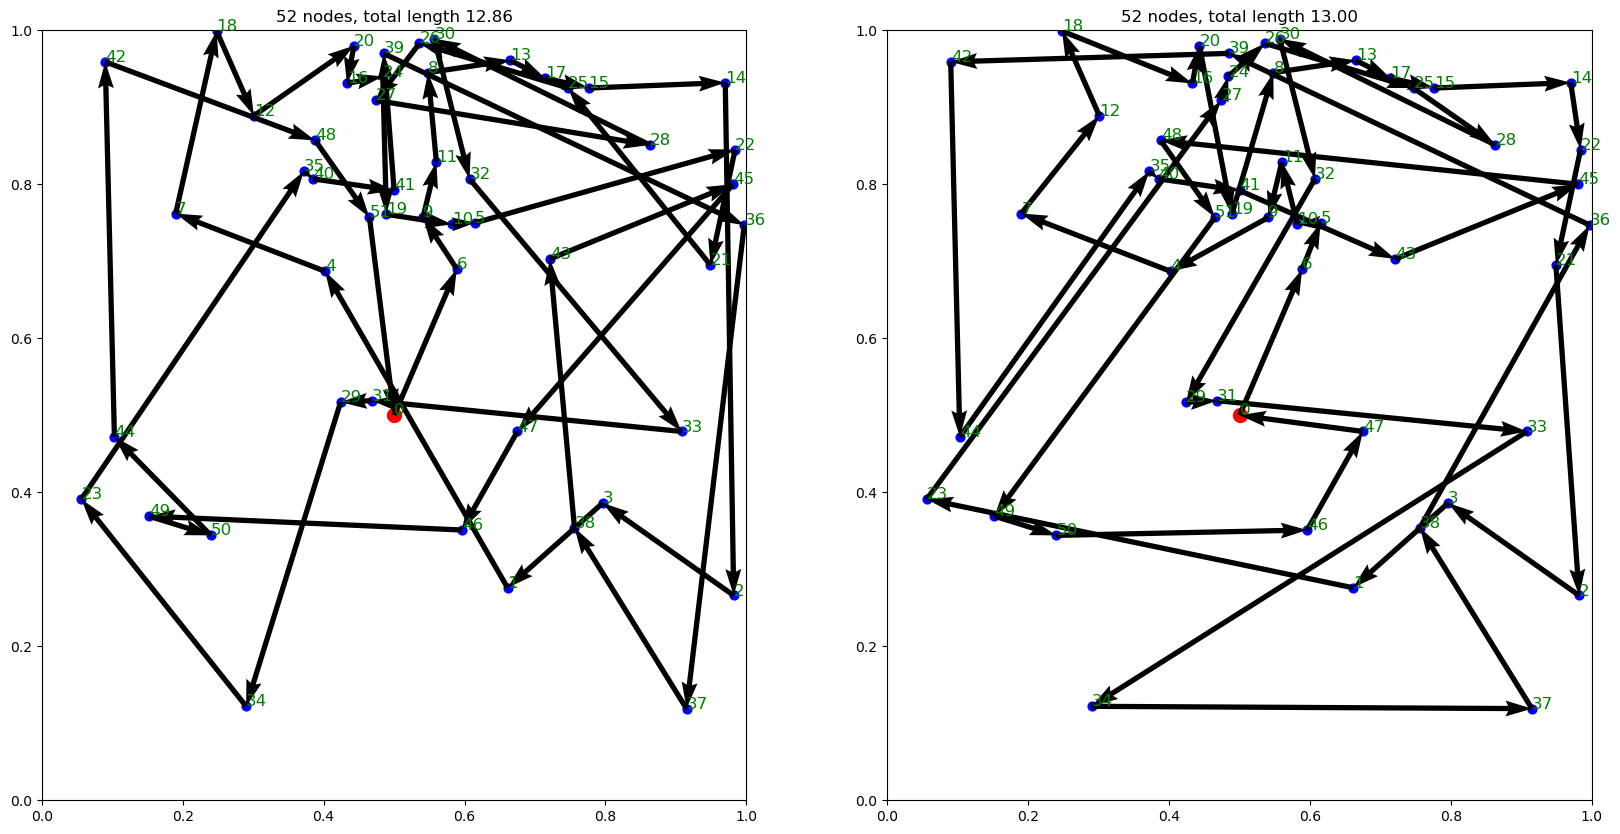

In [48]:
index = 2

#plot model solution and or tools solution side by side
fig, axs = plt.subplots(1, 2, figsize=(20, 10))

plot_tsp(bat['all_nodes'][index].cpu().numpy(), pi_with_depot[index].cpu().numpy(), axs[0])
plot_tsp(bat['all_nodes'][index].cpu().numpy(), bat['tour_nodes'][index].cpu().numpy(), axs[1])

print("dod = ", str(np.sum(bat['arrival_times'][index].cpu().numpy() > 0)/len(bat['arrival_times'][index].cpu().numpy())))

plt.show()

In [5]:
def plot_qv(xy, tour, ax1):
    """
    Plot the TSP tour on matplotlib axis ax1.
    """    
    xs, ys = xy[tour].transpose()
    dx = np.roll(xs, -1) - xs
    dy = np.roll(ys, -1) - ys
    if len(xy) != len(tour) and len(tour) > 1:
        xs = xs[:-1]
        ys = ys[:-1]
        dx = dx[:-1]
        dy = dy[:-1]
    d = np.sqrt(dx * dx + dy * dy)
    lengths = d.cumsum()
    
    qv = ax1.quiver(
        xs, ys, dx, dy,
        scale_units='xy',
        angles='xy',
        scale=1,
    )
    
    return qv, lengths[-1]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/tmp/ipykernel_311833/3606804103.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base = plt.cm.get_cmap(base_cmap)


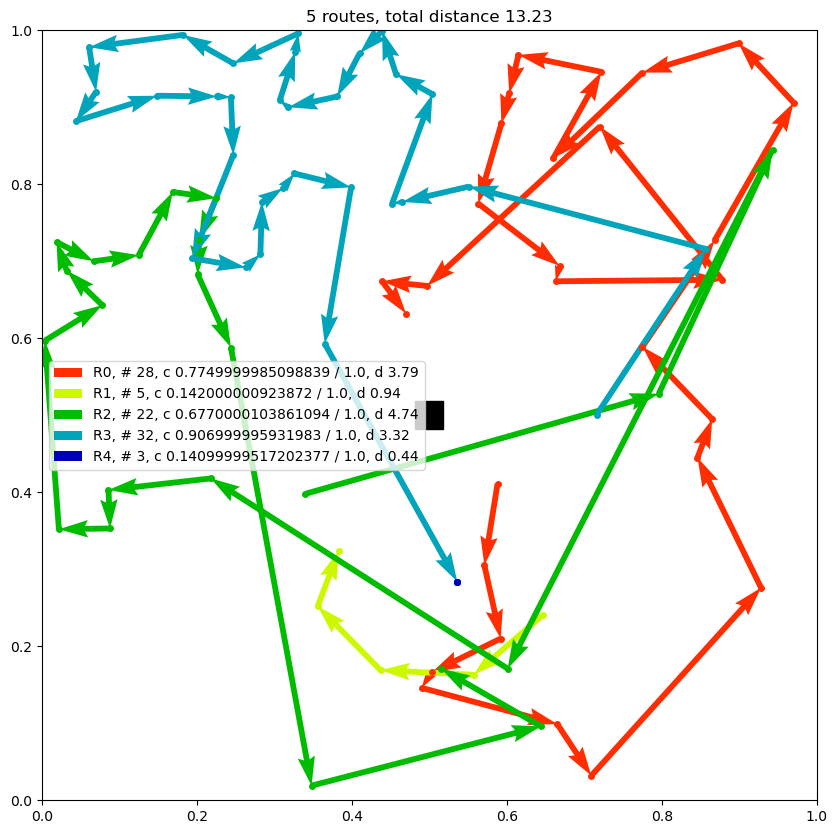

In [27]:
index = 0
fig, axs = plt.subplots(figsize=(10, 10))
#plot_vehicle_routes(bat['all_nodes'][index], bat['demand'][index], 1.0, pi_with_depot[index], axs[0], visualize_demands=True)
plot_vehicle_routes(bat['all_nodes'][index], bat['demand'][index], 1.0, torch.tensor(bat['tour_nodes'][index].cpu().numpy()), axs, visualize_demands=False)

In [76]:
# plot an animation of OR-Tools PDCVRP solution

import matplotlib.animation as animation
from IPython.display import HTML

visit_times = bat['visit_times'][index].cpu().numpy()
visit_times_unpad = visit_times[visit_times != -1]
arrival_times = bat['arrival_times'][index].cpu().numpy()
tour = bat['tour_nodes'][index]
tour_unpad = tour[tour != -1][:-1]
loc = bat['all_nodes'][index]
demands = bat['demand'][index]

total_routes = len([r[r!=0] for r in np.split(tour_unpad.cpu().numpy(), np.where(tour_unpad==0)[0]) if (r != 0).any()])

fig, ax = plt.subplots(figsize=(10, 10))

def update(i):
    current_time = visit_times_unpad[i]
    nodes_present = arrival_times <= current_time
    ax.clear()
    vehicle_routes = plot_vehicle_routes_anim(loc[nodes_present], demands[nodes_present], 1.0, tour_unpad[:i+1], total_routes, ax)
    # scatter nodes
    scat = ax.scatter(loc[nodes_present].numpy().transpose()[0], loc[nodes_present].numpy().transpose()[1], s=40, color='black')
 
    return vehicle_routes, scat
    

ani = animation.FuncAnimation(fig, update, frames=len(tour_unpad), interval=200)

html = HTML(ani.to_html5_video())

display(html)

plt.close()
    

/tmp/ipykernel_311833/3606804103.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base = plt.cm.get_cmap(base_cmap)


In [49]:
import matplotlib.animation as animation
from IPython.display import HTML

visit_times = bat['visit_times'][index].cpu().numpy()
arrival_times = bat['arrival_times'][index].cpu().numpy()
tour = bat['tour_nodes'][index].cpu().numpy()
loc = bat['all_nodes'][index].cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 10))

def update(i):
    current_time = visit_times[i]
    nodes_present = arrival_times <= current_time
    ax.clear()
    qv = plot_qv(loc[nodes_present], tour[:i+1], ax)
    # Scatter nodes
    scat = ax.scatter(loc[nodes_present].transpose()[0], loc[nodes_present].transpose()[1], s=40, color='blue')
    # Starting node
    ax.scatter([loc[0]], [loc[0]], s=100, color='red')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title('{} visited nodes, {} available nodes, time {:.2f}'.format(len(tour[:i+1]), sum(nodes_present), current_time))

    return (qv, scat)

ani = animation.FuncAnimation(fig, update, frames=len(tour), interval=200)

html = HTML(ani.to_html5_video())

display(html)

plt.close()

In [50]:
# Show two animations side by side, the model solution and the OR Tools solution

import matplotlib.animation as animation
from IPython.display import HTML

ort_visit_times = bat['visit_times'][index].cpu().numpy()[:-1]
arrival_times = bat['arrival_times'][index].cpu().numpy()
ort_tour = bat['tour_nodes'][index].cpu().numpy()
loc = bat['all_nodes'][index].cpu().numpy()
model_tour = pi_with_depot[index].cpu().numpy()
model_visit_times = np.insert(np.array(model_visits[index]), 0, 0)

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

def update(i):
    current_time_ort = ort_visit_times[i]
    current_time_model = model_visit_times[i]
    nodes_present_ort = arrival_times <= current_time_ort
    nodes_present_model = arrival_times <= current_time_model
    axs[0].clear()
    axs[1].clear()
    qv1, d1 = plot_qv(loc[nodes_present_ort], ort_tour[:i+1], axs[0])
    qv2, d2 = plot_qv(loc[nodes_present_model], model_tour[:i+1], axs[1])
    # Scatter nodes
    scat1 = axs[0].scatter(loc[nodes_present_ort].transpose()[0], loc[nodes_present_ort].transpose()[1], s=40, color='blue')
    scat2 = axs[1].scatter(loc[nodes_present_model].transpose()[0], loc[nodes_present_model].transpose()[1], s=40, color='blue')
    # Starting node
    axs[0].scatter([loc[0]], [loc[0]], s=100, color='red')
    axs[0].set_xlim(0, 1)
    axs[0].set_ylim(0, 1)
    axs[0].set_title('OR Tools, {} visited nodes, {} available nodes, time {:.2f}, distance {:.2f}'.format(len(ort_tour[:i+1]), sum(nodes_present_ort), current_time_ort, d1))
    axs[1].scatter([loc[0]], [loc[0]], s=100, color='red')
    axs[1].set_xlim(0, 1)
    axs[1].set_ylim(0, 1)
    axs[1].set_title('RL Model, {} visited nodes, {} available nodes, time {:.2f}, distance {:.2f}'.format(len(model_tour[:i+1]), sum(nodes_present_model), current_time_model, d2))

    return (qv1, qv2, scat1, scat2)

ani = animation.FuncAnimation(fig, update, frames=len(loc), interval=400)

html = HTML(ani.to_html5_video())

display(html)

plt.close()

In [12]:
pi_with_depot

tensor([[ 0,  6, 28, 13, 38, 19, 16, 20, 18, 12, 40, 39,  2, 32, 37, 52, 15, 42,
         34, 35, 46,  3, 36,  4, 50, 33,  1, 58, 48, 14, 63, 56, 60, 45, 65, 24,
         21, 54, 11, 43, 71, 25,  7,  5,  9,  8, 47, 27, 70, 73, 59, 69, 49, 66,
         79, 76, 64, 53, 80, 81, 67, 62, 78, 83, 61, 68, 10, 87, 74, 30, 26, 29,
         57, 51, 72, 41, 23, 31, 44, 77, 55, 22, 75, 17, 86, 82, 85, 84],
        [ 0, 13,  9, 45, 48, 41, 18, 14, 36, 15, 27,  3, 20, 49, 35, 33, 19, 22,
         54, 21, 42, 55, 44, 40, 57, 43, 30, 29, 28, 39, 56, 50, 38, 17, 31, 16,
         59, 32, 46,  2, 47, 64, 53, 37, 11,  6,  4,  5, 34,  8, 61, 52, 76, 51,
          7, 10, 12, 58, 78, 69, 63, 73, 70, 68, 72, 82, 60, 77, 81, 74, 83, 66,
         62, 71, 87, 86, 26, 65, 24, 25, 23, 67,  1, 85, 79, 75, 80, 84],
        [ 0,  1,  8,  5,  7,  4, 13,  6, 11, 57, 18, 55, 16, 56, 65, 28, 46, 17,
         58, 14, 59, 42, 61, 62, 54, 60, 50, 51, 45, 52, 37, 64, 31, 44, 47, 53,
         24, 70,  2, 29, 43, 49, 48, 23, 3